# CineMatch
### An Intelligent Movie Recommendation and User Preference Analysis System
### 1. Project Introduction

CineMatch is a machine learning-based movie recommendation system that suggests movies according to the user's current mood, preferred genre, movie characteristics, and rating preferences.

The system combines content-based filtering, collaborative filtering, and user clustering to generate personalized movie recommendations.

### 2. Problem Statement

Traditional movie recommendation systems may not consider the user's current mood when suggesting movies. CineMatch aims to incorporate mood and genre preferences along with movie similarities and user rating patterns to provide more personalized recommendations.

### 3. Project Objectives

- Recommend movies based on the user's selected mood and genre.
- Identify similar movies using content-based filtering.
- Analyze user ratings to discover preference patterns.
- Group users with similar preferences using K-Means clustering.
- Visualize user preference clusters using PCA.
- Combine multiple recommendation signals into a hybrid recommendation system.
- Evaluate the recommendation system using suitable performance metrics.

### 4. Dataset

The project uses the MovieLens Latest Small dataset, including:

- `movies.csv` — movie titles and genres.
- `ratings.csv` — user ratings for movies.
- `tags.csv` — user-generated movie tags.

### 5.Machine Learning Techniques

1. Content-Based Filtering
2. Collaborative Filtering
3. K-Means Clustering
4. Principal Component Analysis (PCA)

### 6. Expected Outcome

The final system will accept a user's mood and preferred genre and return a ranked list of relevant movie recommendations with match scores.

### 7. Technology Stack

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- MovieLens Dataset

### SECTION 1 — Import Required Libraries

In [41]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
%matplotlib inline

print("All required libraries imported successfully!")

All required libraries imported successfully!


### SECTION 2 — Load and Inspect the Dataset


In [42]:
from pathlib import Path

# Dataset folder path
DATA_DIR = Path(r"C:\Users\manog\Desktop\ML_PROJECT\ml-latest-small")

# Load MovieLens datasets
movies = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")

In [43]:
# Display basic information
print("DATASET LOADED SUCCESSFULLY!")
print("-" * 50)

print(f"Movies  : {movies.shape[0]:,} rows × {movies.shape[1]} columns")
print(f"Ratings : {ratings.shape[0]:,} rows × {ratings.shape[1]} columns")
print(f"Tags    : {tags.shape[0]:,} rows × {tags.shape[1]} columns")

DATASET LOADED SUCCESSFULLY!
--------------------------------------------------
Movies  : 9,742 rows × 3 columns
Ratings : 100,836 rows × 4 columns
Tags    : 3,683 rows × 4 columns


In [44]:
# Display sample records
print("\nMOVIES DATASET")
display(movies.head())



MOVIES DATASET


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [45]:
print("\nRATINGS DATASET")
display(ratings.head())


RATINGS DATASET


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [46]:
print("\nTAGS DATASET")
display(tags.head())


TAGS DATASET


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


### SECTION 3 — DATA CLEANING

In [47]:
# Create copies so the original datasets remain unchanged
movies_clean = movies.copy()
ratings_clean = ratings.copy()
tags_clean = tags.copy()

# 1. Remove duplicate records

movies_clean = movies_clean.drop_duplicates()
ratings_clean = ratings_clean.drop_duplicates()
tags_clean = tags_clean.drop_duplicates()

# 2. Remove rows with missing essential values

movies_clean = movies_clean.dropna(
    subset=["movieId", "title", "genres"]
)

ratings_clean = ratings_clean.dropna(
    subset=["userId", "movieId", "rating"]
)

tags_clean = tags_clean.dropna(
    subset=["userId", "movieId", "tag"]
)

# 3. Clean movie titles and genres

movies_clean["title"] = movies_clean["title"].str.strip()
movies_clean["genres"] = movies_clean["genres"].str.strip()

# 4. Clean and normalize tags

tags_clean["tag"] = (
    tags_clean["tag"]
    .str.strip()
    .str.lower()
)

# Remove empty values
movies_clean = movies_clean[
    (movies_clean["title"] != "") &
    (movies_clean["genres"] != "")
]

tags_clean = tags_clean[
    tags_clean["tag"] != ""
]

# 5. Validate rating values

ratings_clean = ratings_clean[
    ratings_clean["rating"].between(0.5, 5.0) &
    ((ratings_clean["rating"] * 2) % 1 == 0)
]

# 6. Check for invalid movie references

movie_ids = set(movies_clean["movieId"])

invalid_rating_movies = (
    ~ratings_clean["movieId"].isin(movie_ids)
).sum()

invalid_tag_movies = (
    ~tags_clean["movieId"].isin(movie_ids)
).sum()


In [48]:
# 7. Display cleaning results

print("DATA CLEANING COMPLETED")
print("=" * 50)

print("\nDataset sizes:")
print(f"Movies  : {movies.shape}  →  {movies_clean.shape}")
print(f"Ratings : {ratings.shape}  →  {ratings_clean.shape}")
print(f"Tags    : {tags.shape}  →  {tags_clean.shape}")

print("\nMissing values after cleaning:")
print("Movies :", movies_clean.isnull().sum().sum())
print("Ratings:", ratings_clean.isnull().sum().sum())
print("Tags   :", tags_clean.isnull().sum().sum())

print("\nDuplicate rows after cleaning:")
print("Movies :", movies_clean.duplicated().sum())
print("Ratings:", ratings_clean.duplicated().sum())
print("Tags   :", tags_clean.duplicated().sum())

print("\nInvalid movie references:")
print("Ratings referring to unknown movies:", invalid_rating_movies)
print("Tags referring to unknown movies:", invalid_tag_movies)

DATA CLEANING COMPLETED

Dataset sizes:
Movies  : (9742, 3)  →  (9742, 3)
Ratings : (100836, 4)  →  (100836, 4)
Tags    : (3683, 4)  →  (3683, 4)

Missing values after cleaning:
Movies : 0
Ratings: 0
Tags   : 0

Duplicate rows after cleaning:
Movies : 0
Ratings: 0
Tags   : 0

Invalid movie references:
Ratings referring to unknown movies: 0
Tags referring to unknown movies: 0


### SECTION 4 — EXPLORATORY DATA ANALYSIS (EDA)

BASIC DATASET STATISTICS
Total movies: 9742
Total users: 610
Total ratings: 100836
Total tags: 3683

Average rating: 3.5
Median rating: 3.5


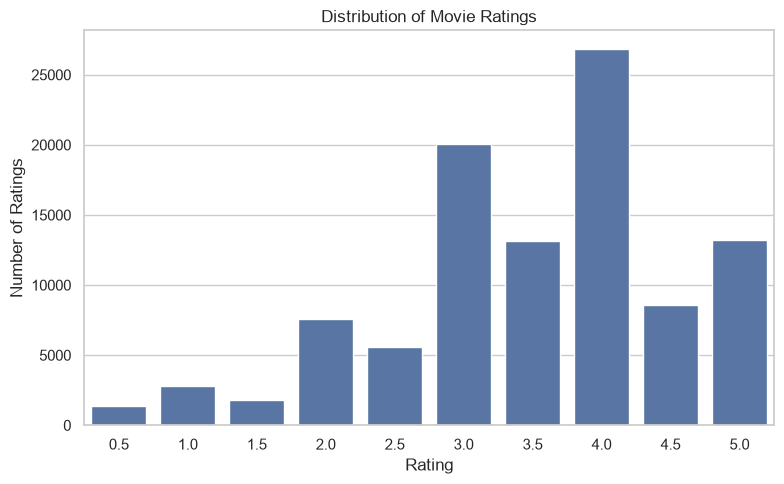

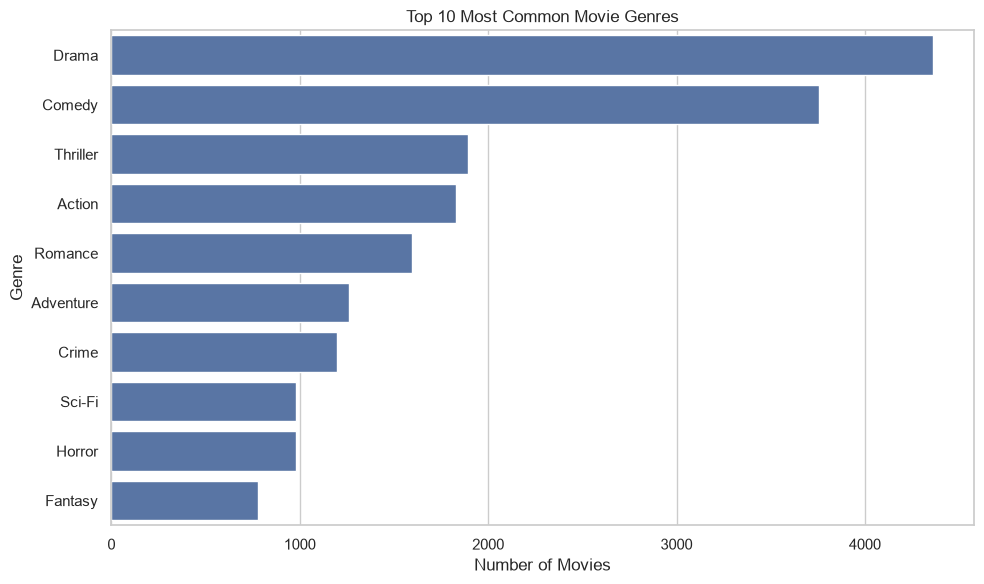


TOP 10 MOST-RATED MOVIES


,title,rating_count
314,Forrest Gump (1994),329
277,"Shawshank Redemption, The (1994)",317
257,Pulp Fiction (1994),307
510,"Silence of the Lambs, The (1991)",279
1938,"Matrix, The (1999)",278
224,Star Wars: Episode IV - A New Hope (1977),251
418,Jurassic Park (1993),238
97,Braveheart (1995),237
507,Terminator 2: Judgment Day (1991),224
461,Schindler's List (1993),220


In [49]:
# ------------------------------------------------------------
# 1. Basic Dataset Statistics
# ------------------------------------------------------------

print("BASIC DATASET STATISTICS")
print("=" * 50)

print("Total movies:", movies_clean["movieId"].nunique())
print("Total users:", ratings_clean["userId"].nunique())
print("Total ratings:", len(ratings_clean))
print("Total tags:", len(tags_clean))

print("\nAverage rating:", round(ratings_clean["rating"].mean(), 2))
print("Median rating:", ratings_clean["rating"].median())


# ------------------------------------------------------------
# 2. Distribution of Movie Ratings
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings_clean,
    x="rating"
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Most Common Movie Genres
# ------------------------------------------------------------

genre_counts = (
    movies_clean["genres"]
    .str.split("|")
    .explode()
)

# Remove movies without a listed genre
genre_counts = genre_counts[
    genre_counts != "(no genres listed)"
]

top_genres = genre_counts.value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Most Common Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Top 10 Most-Rated Movies
# ------------------------------------------------------------

movie_rating_counts = (
    ratings_clean
    .groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

top_rated_movies = (
    movie_rating_counts
    .merge(
        movies_clean[["movieId", "title"]],
        on="movieId",
        how="left"
    )
    .sort_values(
        "rating_count",
        ascending=False
    )
    .head(10)
)

print("\nTOP 10 MOST-RATED MOVIES")
display(top_rated_movies[["title", "rating_count"]])

### SECTION 5 — CONTENT-BASED RECOMMENDATION

In [50]:
# ------------------------------------------------------------
# 1. Prepare movie genre features
# ------------------------------------------------------------

movies_content = movies_clean[
    ["movieId", "title", "genres"]
].copy()

# Convert "|" between genres into spaces
movies_content["genres_text"] = (
    movies_content["genres"]
    .str.replace("|", " ", regex=False)
    .str.replace("(no genres listed)", "", regex=False)
    .str.strip()
)

print("Movie content data prepared!")
display(movies_content.head())


# ------------------------------------------------------------
# 2. Convert genres into TF-IDF features
# ------------------------------------------------------------

tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(
    movies_content["genres_text"]
)

print("\nTF-IDF MATRIX")
print("Matrix shape:", tfidf_matrix.shape)
print("Number of movies:", movies_content.shape[0])
print("Number of genre features:",
      len(tfidf.get_feature_names_out()))


# ------------------------------------------------------------
# 3. Calculate cosine similarity
# ------------------------------------------------------------

cosine_sim = cosine_similarity(tfidf_matrix)

print("\nCOSINE SIMILARITY")
print("Similarity matrix shape:", cosine_sim.shape)
print("Similarity of a movie with itself:",
      cosine_sim[0][0])


# ------------------------------------------------------------
# 4. Create content-based recommendation function
# ------------------------------------------------------------

def recommend_similar_movies(movie_title, num_recommendations=10):

    # Find the selected movie
    matching_movies = movies_content[
        movies_content["title"].str.contains(
            movie_title,
            case=False,
            regex=False,
            na=False
        )
    ]

    if matching_movies.empty:
        print("Movie not found. Try another title.")
        return

    # Get movie index
    movie_index = matching_movies.index[0]

    # Get similarity scores
    similarity_scores = list(
        enumerate(cosine_sim[movie_index])
    )

    # Sort by similarity
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Remove the selected movie itself
    similarity_scores = [
        item
        for item in similarity_scores
        if item[0] != movie_index
    ]

    # Select top recommendations
    top_movies = similarity_scores[
        :num_recommendations
    ]

    recommended_indices = [
        item[0] for item in top_movies
    ]

    # Create recommendation table
    recommendations = movies_content.iloc[
        recommended_indices
    ][["title", "genres"]].copy()

    recommendations["similarity_score"] = [
        round(item[1], 3)
        for item in top_movies
    ]

    print(
        f"\nMovies similar to: "
        f"{movies_content.iloc[movie_index]['title']}"
    )

    display(recommendations)


# ------------------------------------------------------------
# 5. Test the content-based recommender
# ------------------------------------------------------------

recommend_similar_movies(
    "Toy Story (1995)",
    num_recommendations=10
)

Movie content data prepared!


,movieId,title,genres,genres_text
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,Comedy



TF-IDF MATRIX
Matrix shape: (9742, 21)
Number of movies: 9742
Number of genre features: 21

COSINE SIMILARITY
Similarity matrix shape: (9742, 9742)
Similarity of a movie with itself: 1.0

Movies similar to: Toy Story (1995)


,title,genres,similarity_score
1706,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
2355,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2809,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3000,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3568,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6194,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6486,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
6948,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
7760,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
8219,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0


### SECTION 6 — COLLABORATIVE FILTERING

In [51]:
# ------------------------------------------------------------
# 1. Create User-Movie Rating Matrix
# ------------------------------------------------------------

user_movie_matrix = ratings_clean.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("USER-MOVIE MATRIX")
print("Matrix shape:", user_movie_matrix.shape)

display(
    user_movie_matrix.iloc[:5, :10]
)


# ------------------------------------------------------------
# 2. Calculate User Mean Ratings
# ------------------------------------------------------------

user_means = user_movie_matrix.mean(axis=1)

# Center each user's ratings around their average
centered = user_movie_matrix.sub(
    user_means,
    axis=0
)


# ------------------------------------------------------------
# 3. Calculate User Similarity
# ------------------------------------------------------------

observed = user_movie_matrix.notna().astype(float)

C = centered.fillna(0).values
M = observed.values

# Calculate similarity between users
numer = C @ C.T

sq = C ** 2

denom = (
    np.sqrt(sq @ M.T)
    * np.sqrt(M @ sq.T)
)

sim = np.divide(
    numer,
    denom,
    out=np.zeros_like(numer),
    where=denom > 0
)


# ------------------------------------------------------------
# 4. Apply Similarity Shrinkage
# ------------------------------------------------------------

shared = M @ M.T

MIN_SHARED = 5

shrink = shared / (shared + 10)

sim = sim * shrink

# Ignore users with very few movies in common
sim[shared < MIN_SHARED] = 0

# A user should not be similar to themselves
np.fill_diagonal(sim, 0)

user_sim_df = pd.DataFrame(
    sim,
    index=user_movie_matrix.index,
    columns=user_movie_matrix.index
)


# ------------------------------------------------------------
# 5. Collaborative Recommendation Function
# ------------------------------------------------------------

def recommend_collaborative(
    user_id,
    n=10,
    k=30,
    min_neighbors=3,
    damping=2.0
):

    if user_id not in user_movie_matrix.index:
        raise ValueError(
            f"Unknown user_id: {user_id}"
        )

    # Select the most similar users
    sims = user_sim_df.loc[user_id]

    neighbors = (
        sims[sims > 0]
        .nlargest(k)
    )

    if neighbors.empty:
        return pd.DataFrame()

    # Ratings of similar users
    nb_centered = centered.loc[
        neighbors.index
    ]

    nb_observed = nb_centered.notna()

    # Weighted rating deviations
    numer = (
        nb_centered
        .fillna(0)
        .mul(neighbors.values, axis=0)
        .sum()
    )

    denom = (
        nb_observed
        .mul(neighbors.values, axis=0)
        .abs()
        .sum()
    )

    counts = nb_observed.sum()

    # Predict ratings
    deviation = numer / (
        denom + damping
    )

    raw_score = (
        user_means[user_id]
        + deviation
    )

    predicted_rating = raw_score.clip(
        0.5,
        5.0
    )

    # Exclude movies already rated by the user
    already_rated = (
        user_movie_matrix
        .loc[user_id]
        .notna()
    )

    valid = (
        (~already_rated)
        & (counts >= min_neighbors)
    )

    # Create recommendation table
    recommendations = pd.DataFrame({
        "movieId": raw_score.index[valid],
        "raw_score": raw_score[valid].values,
        "predicted_rating": predicted_rating[valid].values,
        "n_neighbors": counts[valid].values
    })

    recommendations = (
        recommendations
        .sort_values(
            "raw_score",
            ascending=False
        )
        .head(n)
    )

    # Add movie information
    recommendations = recommendations.merge(
        movies_clean[
            ["movieId", "title", "genres"]
        ],
        on="movieId",
        how="left"
    )

    return recommendations


# ------------------------------------------------------------
# 6. Test Collaborative Filtering
# ------------------------------------------------------------

user_id = 1

collaborative_recommendations = (
    recommend_collaborative(user_id)
)

print(
    f"Collaborative recommendations "
    f"for User {user_id}"
)

display(
    collaborative_recommendations[
        [
            "title",
            "genres",
            "predicted_rating",
            "n_neighbors"
        ]
    ]
)

USER-MOVIE MATRIX
Matrix shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Collaborative recommendations for User 1


,title,genres,predicted_rating,n_neighbors
0,Wallace & Gromit: The Wrong Trousers (1993),Animation|Children|Comedy|Crime,5.000000,6
1,"Shawshank Redemption, The (1994)",Crime|Drama,5.000000,14
2,Wallace & Gromit: The Best of Aardman Animatio...,Adventure|Animation|Comedy,4.983473,4
3,Casablanca (1942),Drama|Romance,4.962458,7
4,"Godfather, The (1972)",Crime|Drama,4.931564,10
5,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.924355,7
6,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,4.915729,6
7,Spirited Away (Sen to Chihiro no kamikakushi) ...,Adventure|Animation|Fantasy,4.895078,6
8,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,4.894439,3
9,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller,4.886605,5


### SECTION 7 — USER CLUSTERING

USER CLUSTERING DATA
User clustering matrix shape: (610, 9724)
Scaled user data shape: (610, 9724)
Missing values after preparation: 0


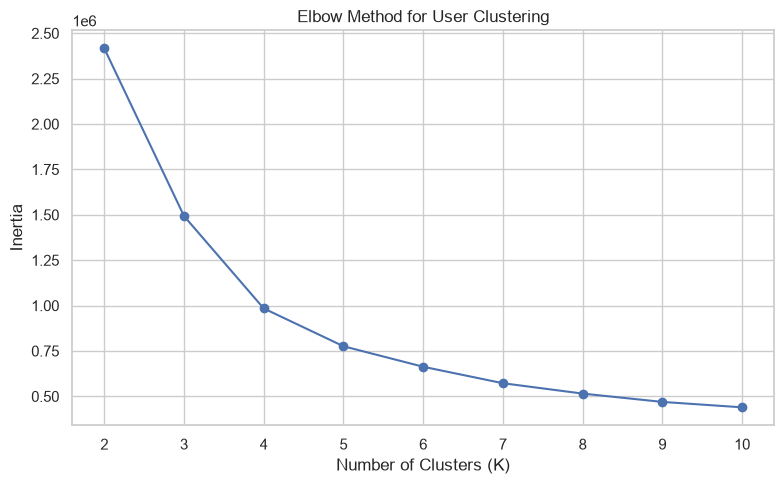


USER CLUSTER LABELS


,userId,Cluster
0,1,2
1,2,0
2,3,1
3,4,3
4,5,0
5,6,3
6,7,3
7,8,3
8,9,3
9,10,3



Number of users in each cluster:


Cluster
0    227
1     52
2    127
3    204
Name: User Count, dtype: int64

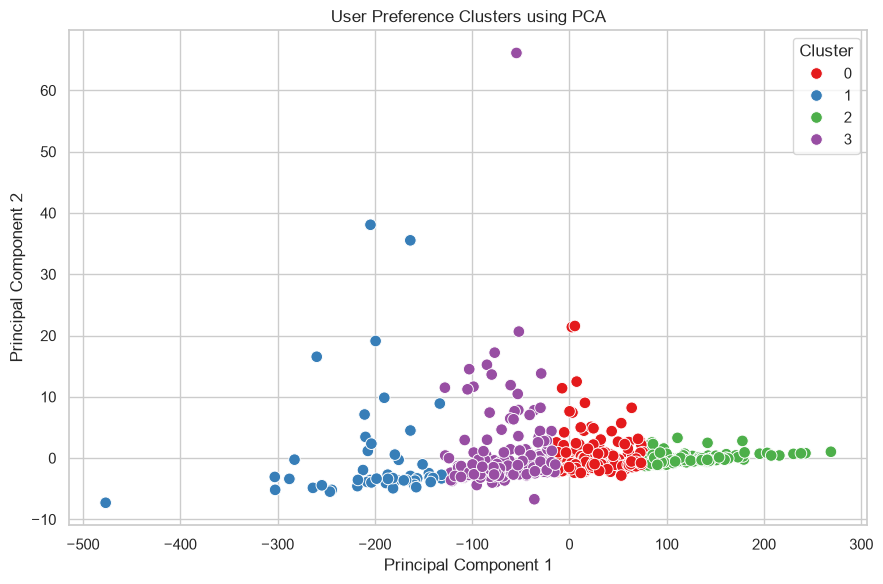

In [52]:
# ------------------------------------------------------------
# 1. Prepare User Data for Clustering
# ------------------------------------------------------------

# Use the user-movie rating matrix
user_cluster_matrix = user_movie_matrix.copy()

# Fill missing ratings with each user's average rating
user_cluster_matrix = user_cluster_matrix.apply(
    lambda row: row.fillna(row.mean()),
    axis=1
)

# Standardize the movie-rating features
scaler = StandardScaler()

user_scaled = scaler.fit_transform(
    user_cluster_matrix
)

print("USER CLUSTERING DATA")
print("=" * 50)
print("User clustering matrix shape:",
      user_cluster_matrix.shape)

print("Scaled user data shape:",
      user_scaled.shape)

print("Missing values after preparation:",
      np.isnan(user_scaled).sum())


# ------------------------------------------------------------
# 2. Find Optimal Number of Clusters
# ------------------------------------------------------------

inertias = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(user_scaled)

    inertias.append(
        kmeans.inertia_
    )


# ------------------------------------------------------------
# 3. Elbow Method Visualization
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.title(
    "Elbow Method for User Clustering"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.xticks(k_values)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Apply K-Means Clustering
# ------------------------------------------------------------

# Based on the original notebook
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

user_clusters = kmeans.fit_predict(
    user_scaled
)


# ------------------------------------------------------------
# 5. Attach Cluster Labels to Users
# ------------------------------------------------------------

user_cluster_labels = pd.DataFrame({
    "userId": user_movie_matrix.index,
    "Cluster": user_clusters
})

print("\nUSER CLUSTER LABELS")
display(
    user_cluster_labels.head(10)
)

print(
    "\nNumber of users in each cluster:"
)

display(
    user_cluster_labels[
        "Cluster"
    ].value_counts()
    .sort_index()
    .rename("User Count")
)


# ------------------------------------------------------------
# 6. Visualize Clusters Using PCA
# ------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

user_pca = pca.fit_transform(
    user_scaled
)

pca_df = pd.DataFrame({
    "PC1": user_pca[:, 0],
    "PC2": user_pca[:, 1],
    "Cluster": user_clusters
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=70
)

plt.title(
    "User Preference Clusters using PCA"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### SECTION 8 — HYBRID RECOMMENDATION

In [53]:
# ------------------------------------------------------------
# 1. Prepare Movie Rating Statistics
# ------------------------------------------------------------

movie_stats = (
    ratings_clean
    .groupby("movieId")["rating"]
    .agg(
        avg_rating="mean",
        rating_count="count"
    )
    .reset_index()
)

movies_hybrid = movies_clean.merge(
    movie_stats,
    on="movieId",
    how="left"
)

movies_hybrid["avg_rating"] = (
    movies_hybrid["avg_rating"].fillna(0)
)

movies_hybrid["rating_count"] = (
    movies_hybrid["rating_count"]
    .fillna(0)
    .astype(int)
)

global_avg_rating = ratings_clean["rating"].mean()

print("HYBRID RECOMMENDATION DATA")
print("=" * 50)
print("Movies available:", len(movies_hybrid))
print(
    "Movies with ratings:",
    (movies_hybrid["rating_count"] > 0).sum()
)
print(
    "Global average rating:",
    round(global_avg_rating, 3)
)

display(
    movies_hybrid[
        [
            "movieId",
            "title",
            "genres",
            "avg_rating",
            "rating_count"
        ]
    ].head()
)


# ------------------------------------------------------------
# 2. Create Hybrid Recommendation Function
# ------------------------------------------------------------

def recommend_hybrid(
    user_id,
    movie_title,
    num_recommendations=10,
    content_weight=0.6,
    collaborative_weight=0.4
):

    if user_id not in user_movie_matrix.index:
        raise ValueError(
            f"User ID {user_id} not found."
        )

    # Find the reference movie
    matched = movies_content[
        movies_content["title"].str.casefold()
        == movie_title.casefold()
    ]

    if matched.empty:
        raise ValueError(
            f"Movie not found: {movie_title}"
        )

    reference_id = matched.iloc[0]["movieId"]

    reference_idx = movies_content.index[
        movies_content["movieId"] == reference_id
    ][0]

    # --------------------------------------------------------
    # Content-Based Score
    # --------------------------------------------------------

    content_scores = pd.Series(
        cosine_sim[reference_idx],
        index=movies_content["movieId"]
    )

    # Movies already rated by the user
    rated_movie_ids = set(
        user_movie_matrix
        .loc[user_id]
        .dropna()
        .index
    )

    # --------------------------------------------------------
    # Collaborative Score
    # --------------------------------------------------------

    collab_recommendations = recommend_collaborative(
        user_id=user_id,
        n=len(movies_clean),
        k=30,
        min_neighbors=3,
        damping=2.0
    )

    if not collab_recommendations.empty:

        collab_scores = (
            collab_recommendations
            .set_index("movieId")["predicted_rating"]
        )

        # Normalize ratings to 0–1
        collab_scores = (
            (collab_scores - 0.5) / 4.5
        )

    else:
        collab_scores = pd.Series(
            dtype=float
        )

    # --------------------------------------------------------
    # Combine Candidate Movies
    # --------------------------------------------------------

    candidates = movies_hybrid[
        ~movies_hybrid["movieId"].isin(
            rated_movie_ids
        )
    ].copy()

    # Remove the reference movie
    candidates = candidates[
        candidates["movieId"] != reference_id
    ]

    # Add content scores
    candidates["content_score"] = (
        candidates["movieId"]
        .map(content_scores)
        .fillna(0)
    )

    # Add collaborative scores
    candidates["collaborative_score"] = (
        candidates["movieId"]
        .map(collab_scores)
        .fillna(0)
    )

    # --------------------------------------------------------
    # Calculate Hybrid Score
    # --------------------------------------------------------

    candidates["hybrid_score"] = (
        content_weight
        * candidates["content_score"]
        +
        collaborative_weight
        * candidates["collaborative_score"]
    )

    # Sort and return recommendations
    recommendations = (
        candidates
        .sort_values(
            "hybrid_score",
            ascending=False
        )
        .head(num_recommendations)
        .reset_index(drop=True)
    )

    return recommendations[
        [
            "movieId",
            "title",
            "genres",
            "avg_rating",
            "rating_count",
            "content_score",
            "collaborative_score",
            "hybrid_score"
        ]
    ]


# ------------------------------------------------------------
# 3. Test Hybrid Recommendation
# ------------------------------------------------------------

user_id = 1
movie_title = "Toy Story (1995)"

hybrid_recommendations = recommend_hybrid(
    user_id=user_id,
    movie_title=movie_title,
    num_recommendations=10
)

print(
    f"Hybrid recommendations for User {user_id}"
)
print(
    f"Reference movie: {movie_title}"
)

display(hybrid_recommendations)

HYBRID RECOMMENDATION DATA
Movies available: 9742
Movies with ratings: 9724
Global average rating: 3.502


,movieId,title,genres,avg_rating,rating_count
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.920930,215
1,2,Jumanji (1995),Adventure|Children|Fantasy,3.431818,110
2,3,Grumpier Old Men (1995),Comedy|Romance,3.259615,52
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,2.357143,7
4,5,Father of the Bride Part II (1995),Comedy,3.071429,49


Hybrid recommendations for User 1
Reference movie: Toy Story (1995)


,movieId,title,genres,avg_rating,rating_count,content_score,collaborative_score,hybrid_score
0,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,132,1.000000,0.919737,0.967895
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,97,1.000000,0.894663,0.957865
2,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,45,1.000000,0.863177,0.945271
3,4519,"Land Before Time, The (1988)",Adventure|Animation|Children|Fantasy,3.333333,9,0.963534,0.846388,0.916675
4,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,170,0.933286,0.885250,0.914072
5,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,31,0.939012,0.873823,0.912937
6,4366,Atlantis: The Lost Empire (2001),Adventure|Animation|Children|Fantasy,3.342105,19,0.963534,0.806354,0.900662
7,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,141,0.875626,0.905082,0.887408
8,5618,Spirited Away (Sen to Chihiro no kamikakushi) ...,Adventure|Animation|Fantasy,4.155172,87,0.820688,0.976684,0.883086
9,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,85,0.875626,0.880929,0.877747


### SECTION 9 — TESTING


User 1 | Reference movie: Toy Story (1995)
------------------------------------------------------------


,title,genres,avg_rating,content_score,collaborative_score,hybrid_score
0,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,1.000000,0.919737,0.967895
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,1.000000,0.894663,0.957865
2,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,1.000000,0.863177,0.945271
3,"Land Before Time, The (1988)",Adventure|Animation|Children|Fantasy,3.333333,0.963534,0.846388,0.916675
4,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,0.933286,0.885250,0.914072
5,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,0.939012,0.873823,0.912937
6,Atlantis: The Lost Empire (2001),Adventure|Animation|Children|Fantasy,3.342105,0.963534,0.806354,0.900662
7,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,0.875626,0.905082,0.887408
8,Spirited Away (Sen to Chihiro no kamikakushi) ...,Adventure|Animation|Fantasy,4.155172,0.820688,0.976684,0.883086
9,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,0.875626,0.880929,0.877747



User 1 | Reference movie: Jumanji (1995)
------------------------------------------------------------


,title,genres,avg_rating,content_score,collaborative_score,hybrid_score
0,Harry Potter and the Sorcerer's Stone (a.k.a. ...,Adventure|Children|Fantasy,3.761682,1.000000,0.849315,0.939726
1,"Chronicles of Narnia: The Lion, the Witch and ...",Adventure|Children|Fantasy,3.443548,1.000000,0.757822,0.903129
2,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy,4.106061,0.784187,0.970993,0.858909
3,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,0.813578,0.919737,0.856042
4,Field of Dreams (1989),Children|Drama|Fantasy,3.517857,0.809616,0.914682,0.851642
5,"Lord of the Rings: The Two Towers, The (2002)",Adventure|Fantasy,4.021277,0.784187,0.945101,0.848552
6,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,0.813578,0.894663,0.846012
7,"Land Before Time, The (1988)",Adventure|Animation|Children|Fantasy,3.333333,0.844369,0.846388,0.845176
8,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,0.813578,0.863177,0.833417
9,Atlantis: The Lost Empire (2001),Adventure|Animation|Children|Fantasy,3.342105,0.844369,0.806354,0.829163



User 10 | Reference movie: Pulp Fiction (1994)
------------------------------------------------------------


...

,title,genres,predicted_rating,n_neighbors
0,Blade Runner (1982),Action|Sci-Fi|Thriller,3.676340,8
1,"Jungle Book, The (1967)",Animation|Children|Comedy|Musical,3.659902,3
2,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,3.614716,5
3,Indiana Jones and the Last Crusade (1989),Action|Adventure,3.612202,7
4,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,3.610616,12



Recommendations for User 50
--------------------------------------------------


,title,genres,predicted_rating,n_neighbors
0,"Godfather: Part II, The (1974)",Crime|Drama,3.681837,19
1,Casablanca (1942),Drama|Romance,3.667527,16
2,Office Space (1999),Comedy|Crime,3.632259,13
3,American Beauty (1999),Drama|Romance,3.627518,19
4,Schindler's List (1993),Drama|War,3.605565,16



RECOMMENDATION OUTPUT CHECK
Number of recommendations: 10
Duplicate movie IDs: 0
Missing movie titles: 0
Missing hybrid scores: 0

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE
0,Global Mean Baseline,0.8287,1.0409
1,Collaborative Filtering,0.6551,0.8586
2,Hybrid Model,0.6731,0.8736


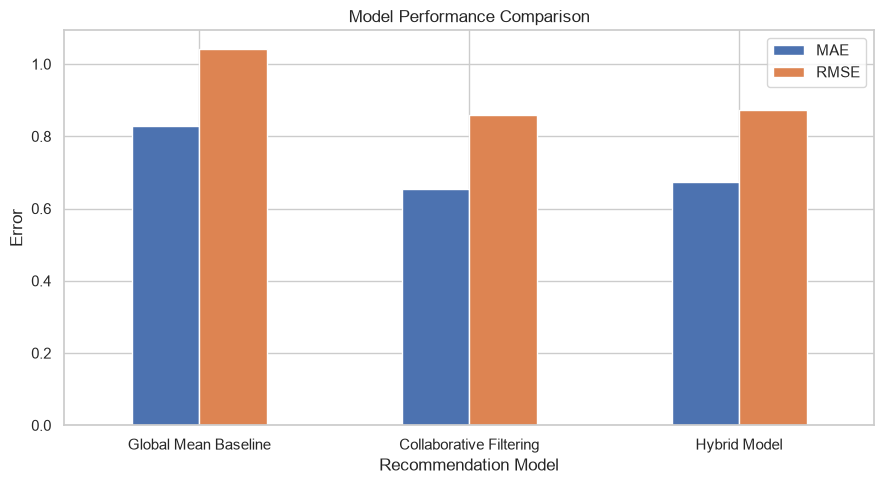

In [54]:
# ------------------------------------------------------------
# 1. Test Different Users and Movies
# ------------------------------------------------------------

test_cases = [
    (1, "Toy Story (1995)"),
    (1, "Jumanji (1995)"),
    (10, "Pulp Fiction (1994)")
]

for user_id, movie_title in test_cases:

    print(
        f"\nUser {user_id} | "
        f"Reference movie: {movie_title}"
    )

    print("-" * 60)

    try:

        results = recommend_hybrid(
            user_id=user_id,
            movie_title=movie_title,
            num_recommendations=10
        )

        display(
            results[
                [
                    "title",
                    "genres",
                    "avg_rating",
                    "content_score",
                    "collaborative_score",
                    "hybrid_score"
                ]
            ]
        )

    except Exception as e:

        print(f"Error: {e}")


# ------------------------------------------------------------
# 2. Test Collaborative Filtering for Different Users
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COLLABORATIVE FILTERING TEST")
print("=" * 60)

test_users = [1, 10, 50]

for user_id in test_users:

    print(f"\nRecommendations for User {user_id}")
    print("-" * 50)

    try:

        results = recommend_collaborative(
            user_id=user_id,
            n=5
        )

        display(
            results[
                [
                    "title",
                    "genres",
                    "predicted_rating",
                    "n_neighbors"
                ]
            ]
        )

    except Exception as e:

        print(f"Error: {e}")


# ------------------------------------------------------------
# 3. Check Recommendation Output
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("RECOMMENDATION OUTPUT CHECK")
print("=" * 60)

sample_result = recommend_hybrid(
    user_id=1,
    movie_title="Toy Story (1995)",
    num_recommendations=10
)

print(
    "Number of recommendations:",
    len(sample_result)
)

print(
    "Duplicate movie IDs:",
    sample_result["movieId"].duplicated().sum()
)

print(
    "Missing movie titles:",
    sample_result["title"].isna().sum()
)

print(
    "Missing hybrid scores:",
    sample_result["hybrid_score"].isna().sum()
)


# ------------------------------------------------------------
# 4. Compare Model Performance
# ------------------------------------------------------------

# Values obtained from the evaluation
# performed in the original notebook

model_comparison = pd.DataFrame({
    "Model": [
        "Global Mean Baseline",
        "Collaborative Filtering",
        "Hybrid Model"
    ],
    "MAE": [
        0.8287,
        0.6551,
        0.6731
    ],
    "RMSE": [
        1.0409,
        0.8586,
        0.8736
    ]
})

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    model_comparison
)


# ------------------------------------------------------------
# 5. Visualize Model Performance
# ------------------------------------------------------------

model_comparison.set_index(
    "Model"
)[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.xlabel("Recommendation Model")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### SECTION 10 — MOOD-AWARE RECOMMENDATION

In [55]:
# ------------------------------------------------------------
# 1. Define Mood-to-Genre Mapping
# ------------------------------------------------------------

mood_genre_map = {
    "Happy": [
        "Comedy",
        "Animation",
        "Musical",
        "Children"
    ],

    "Sad": [
        "Drama",
        "Romance"
    ],

    "Excited": [
        "Action",
        "Adventure",
        "Thriller"
    ],

    "Relaxed": [
        "Comedy",
        "Romance",
        "Animation"
    ],

    "Romantic": [
        "Romance",
        "Drama",
        "Comedy"
    ],

    "Adventurous": [
        "Adventure",
        "Action",
        "Fantasy"
    ],

    "Scared": [
        "Horror",
        "Thriller",
        "Mystery"
    ],

    "Thoughtful": [
        "Drama",
        "Mystery",
        "Documentary"
    ],

    "Nostalgic": [
        "Drama",
        "Romance",
        "Comedy"
    ],

    "Angry": [
        "Action",
        "Thriller",
        "Crime"
    ]
}

print("AVAILABLE MOODS")
print("=" * 50)

for mood, genres in mood_genre_map.items():
    print(f"{mood}: {', '.join(genres)}")


# ------------------------------------------------------------
# 2. Create Mood Score
# ------------------------------------------------------------

def calculate_mood_score(movie_genres, mood):
    """
    Calculate how well a movie's genres match the selected mood.

    Score:
    0 = no mood-related genre
    1 = strong mood-related genre match
    """

    if mood not in mood_genre_map:
        raise ValueError(
            f"Unknown mood: {mood}. "
            f"Choose from: {list(mood_genre_map.keys())}"
        )

    movie_genre_list = set(
        str(movie_genres).split("|")
    )

    mood_genres = set(
        mood_genre_map[mood]
    )

    if not movie_genre_list:
        return 0.0

    matched_genres = (
        movie_genre_list
        .intersection(mood_genres)
    )

    # Normalize by the number of mood-related genres
    score = len(matched_genres) / len(mood_genres)

    return min(score, 1.0)


# ------------------------------------------------------------
# 3. Create Mood-Aware Recommendation Function
# ------------------------------------------------------------

def recommend_mood_aware(
    user_id,
    mood,
    preferred_genre=None,
    movie_title=None,
    num_recommendations=10
):

    # Validate mood
    if mood not in mood_genre_map:
        raise ValueError(
            f"Unknown mood: {mood}. "
            f"Choose from: {list(mood_genre_map.keys())}"
        )

    # If no reference movie is supplied, use a popular movie
    if movie_title is None:
        movie_title = "Toy Story (1995)"

    # Generate a larger candidate list first
    candidate_count = min(
        len(movies_clean),
        300
    )

    candidates = recommend_hybrid(
        user_id=user_id,
        movie_title=movie_title,
        num_recommendations=candidate_count
    ).copy()

    if candidates.empty:
        return pd.DataFrame()

    # --------------------------------------------------------
    # Mood Score
    # --------------------------------------------------------

    candidates["mood_score"] = candidates[
        "genres"
    ].apply(
        lambda x: calculate_mood_score(
            x,
            mood
        )
    )

    # --------------------------------------------------------
    # Preferred Genre Score
    # --------------------------------------------------------

    if preferred_genre is not None:

        preferred_genre = preferred_genre.strip()

        candidates["genre_score"] = (
            candidates["genres"]
            .str.split("|")
            .apply(
                lambda genres:
                1.0
                if preferred_genre in genres
                else 0.0
            )
        )

    else:

        candidates["genre_score"] = 0.0

    # --------------------------------------------------------
    # Calculate Final Mood-Aware Score
    # --------------------------------------------------------

    if preferred_genre is not None:

        candidates["mood_aware_score"] = (
            0.50 * candidates["hybrid_score"]
            +
            0.30 * candidates["mood_score"]
            +
            0.20 * candidates["genre_score"]
        )

    else:

        # Without a selected genre, give more importance to mood
        candidates["mood_aware_score"] = (
            0.55 * candidates["hybrid_score"]
            +
            0.45 * candidates["mood_score"]
        )

    # --------------------------------------------------------
    # Sort Final Recommendations
    # --------------------------------------------------------

    recommendations = (
        candidates
        .sort_values(
            "mood_aware_score",
            ascending=False
        )
        .head(num_recommendations)
        .reset_index(drop=True)
    )

    return recommendations[
        [
            "movieId",
            "title",
            "genres",
            "avg_rating",
            "rating_count",
            "hybrid_score",
            "mood_score",
            "genre_score",
            "mood_aware_score"
        ]
    ]


# ------------------------------------------------------------
# 4. Test Mood-Aware Recommendation
# ------------------------------------------------------------

test_cases = [
    (1, "Happy", "Comedy", "Toy Story (1995)"),
    (1, "Adventurous", "Adventure", "Jumanji (1995)"),
    (10, "Excited", "Thriller", "Pulp Fiction (1994)")
]

for user_id, mood, genre, movie_title in test_cases:

    print("\n" + "=" * 70)
    print(
        f"User: {user_id} | "
        f"Mood: {mood} | "
        f"Genre: {genre}"
    )
    print(
        f"Reference Movie: {movie_title}"
    )
    print("=" * 70)

    try:

        results = recommend_mood_aware(
            user_id=user_id,
            mood=mood,
            preferred_genre=genre,
            movie_title=movie_title,
            num_recommendations=10
        )

        display(results)

    except Exception as e:

        print(f"Error: {e}")


# ------------------------------------------------------------
# 5. Check Mood-Aware Recommendation Output
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MOOD-AWARE OUTPUT CHECK")
print("=" * 70)

sample_result = recommend_mood_aware(
    user_id=1,
    mood="Happy",
    preferred_genre="Comedy",
    movie_title="Toy Story (1995)",
    num_recommendations=10
)

print(
    "Number of recommendations:",
    len(sample_result)
)

print(
    "Duplicate movie IDs:",
    sample_result["movieId"].duplicated().sum()
)

print(
    "Missing movie titles:",
    sample_result["title"].isna().sum()
)

print(
    "Missing mood-aware scores:",
    sample_result["mood_aware_score"].isna().sum()
)

print(
    "Selected mood:",
    "Happy"
)

print(
    "Selected genre:",
    "Comedy"
)

display(sample_result)


AVAILABLE MOODS
Happy: Comedy, Animation, Musical, Children
Sad: Drama, Romance
Excited: Action, Adventure, Thriller
Relaxed: Comedy, Romance, Animation
Romantic: Romance, Drama, Comedy
Adventurous: Adventure, Action, Fantasy
Scared: Horror, Thriller, Mystery
Thoughtful: Drama, Mystery, Documentary
Nostalgic: Drama, Romance, Comedy
Angry: Action, Thriller, Crime

User: 1 | Mood: Happy | Genre: Comedy
Reference Movie: Toy Story (1995)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,132,0.967895,0.75,1.0,0.908947
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,97,0.957865,0.75,1.0,0.903933
2,588,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,3.792350,183,0.798199,1.00,1.0,0.899099
3,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,45,0.945271,0.75,1.0,0.897635
4,1907,Mulan (1998),Adventure|Animation|Children|Comedy|Drama|Musi...,3.566667,45,0.772385,1.00,1.0,0.886192
5,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,170,0.914072,0.75,1.0,0.882036
6,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,31,0.912937,0.75,1.0,0.881468
7,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,141,0.887408,0.75,1.0,0.868704
8,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Ro...,3.576087,92,0.736643,1.00,1.0,0.868321
9,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,85,0.877747,0.75,1.0,0.863873



User: 1 | Mood: Adventurous | Genre: Adventure
Reference Movie: Jumanji (1995)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,31,0.807905,1.000000,1.0,0.903952
1,122926,Untitled Spider-Man Reboot (2017),Action|Adventure|Fantasy,4.156250,16,0.770580,1.000000,1.0,0.885290
2,143355,Wonder Woman (2017),Action|Adventure|Fantasy,3.307692,13,0.769392,1.000000,1.0,0.884696
3,7153,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy,4.118919,185,0.768678,1.000000,1.0,0.884339
4,4896,Harry Potter and the Sorcerer's Stone (a.k.a. ...,Adventure|Children|Fantasy,3.761682,107,0.939726,0.666667,1.0,0.869863
5,653,Dragonheart (1996),Action|Adventure|Fantasy,3.092308,65,0.736048,1.000000,1.0,0.868024
6,45722,Pirates of the Caribbean: Dead Man's Chest (2006),Action|Adventure|Fantasy,3.506944,72,0.728014,1.000000,1.0,0.864007
7,5463,Reign of Fire (2002),Action|Adventure|Fantasy,2.722222,18,0.723061,1.000000,1.0,0.861530
8,6539,Pirates of the Caribbean: The Curse of the Bla...,Action|Adventure|Comedy|Fantasy,3.778523,149,0.710645,1.000000,1.0,0.855322
9,3000,Princess Mononoke (Mononoke-hime) (1997),Action|Adventure|Animation|Drama|Fantasy,3.958333,48,0.707965,1.000000,1.0,0.853982



User: 10 | Mood: Excited | Genre: Thriller
Reference Movie: Pulp Fiction (1994)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,6016,City of God (Cidade de Deus) (2002),Action|Adventure|Crime|Drama|Thriller,4.146667,75,0.657319,1.000000,1.0,0.828659
1,91542,Sherlock Holmes: A Game of Shadows (2011),Action|Adventure|Comedy|Crime|Mystery|Thriller,3.763158,38,0.604845,1.000000,1.0,0.802422
2,49530,Blood Diamond (2006),Action|Adventure|Crime|Drama|Thriller|War,3.764151,53,0.578243,1.000000,1.0,0.789121
3,2273,Rush Hour (1998),Action|Comedy|Crime|Thriller,3.261905,42,0.728922,0.666667,1.0,0.764461
4,293,Léon: The Professional (a.k.a. The Professiona...,Action|Crime|Drama|Thriller,4.018797,133,0.727746,0.666667,1.0,0.763873
5,8798,Collateral (2004),Action|Crime|Drama|Thriller,3.761364,44,0.718002,0.666667,1.0,0.759001
6,59369,Taken (2008),Action|Crime|Drama|Thriller,3.619048,42,0.712764,0.666667,1.0,0.756382
7,608,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116022,181,0.876460,0.333333,1.0,0.738230
8,185,"Net, The (1995)",Action|Crime|Thriller,3.040179,112,0.675059,0.666667,1.0,0.737530
9,592,Batman (1989),Action|Crime|Thriller,3.428571,189,0.673923,0.666667,1.0,0.736962



MOOD-AWARE OUTPUT CHECK
Number of recommendations: 10
Duplicate movie IDs: 0
Missing movie titles: 0
Missing mood-aware scores: 0
Selected mood: Happy
Selected genre: Comedy


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,132,0.967895,0.75,1.0,0.908947
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,97,0.957865,0.75,1.0,0.903933
2,588,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,3.792350,183,0.798199,1.00,1.0,0.899099
3,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,45,0.945271,0.75,1.0,0.897635
4,1907,Mulan (1998),Adventure|Animation|Children|Comedy|Drama|Musi...,3.566667,45,0.772385,1.00,1.0,0.886192
5,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,170,0.914072,0.75,1.0,0.882036
6,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,31,0.912937,0.75,1.0,0.881468
7,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,141,0.887408,0.75,1.0,0.868704
8,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Ro...,3.576087,92,0.736643,1.00,1.0,0.868321
9,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,85,0.877747,0.75,1.0,0.863873


### Section 11: Testing

In [56]:
# Test different users, moods, genres and reference movies

test_cases = [
    (1, "Happy", "Comedy", "Toy Story (1995)"),
    (1, "Sad", "Drama", "Jumanji (1995)"),
    (10, "Excited", "Action", "Pulp Fiction (1994)"),
    (10, "Romantic", "Romance", "Forrest Gump (1994)"),
    (50, "Scared", "Horror", "Scream (1996)")
]


for user_id, mood, genre, movie_title in test_cases:

    print("\n" + "=" * 80)
    print(f"USER ID          : {user_id}")
    print(f"MOOD             : {mood}")
    print(f"PREFERRED GENRE  : {genre}")
    print(f"REFERENCE MOVIE  : {movie_title}")
    print("=" * 80)

    try:

        results = recommend_mood_aware(
            user_id=user_id,
            mood=mood,
            preferred_genre=genre,
            movie_title=movie_title,
            num_recommendations=10
        )

        if results.empty:
            print("No recommendations found.")

        else:
            display(results)

    except Exception as e:

        print("Error:", e)


# ============================================================
# CHECK MOOD-AWARE RECOMMENDATION
# ============================================================

print("\n" + "=" * 80)
print("MOOD-AWARE MODEL CHECK")
print("=" * 80)

result = recommend_mood_aware(
    user_id=1,
    mood="Happy",
    preferred_genre="Comedy",
    movie_title="Toy Story (1995)",
    num_recommendations=10
)

print("Number of recommendations:", len(result))

print(
    "Duplicate movie IDs:",
    result["movieId"].duplicated().sum()
)

print(
    "Missing titles:",
    result["title"].isna().sum()
)

print(
    "Missing mood scores:",
    result["mood_score"].isna().sum()
)

print(
    "Missing final scores:",
    result["mood_aware_score"].isna().sum()
)

print(
    "Mood scores between 0 and 1:",
    result["mood_score"].between(0, 1).all()
)

print(
    "Final scores sorted correctly:",
    result["mood_aware_score"].is_monotonic_decreasing
)


# ============================================================
# DISPLAY FINAL RECOMMENDATIONS
# ============================================================

print("\n" + "=" * 80)
print("FINAL MOOD-AWARE RECOMMENDATIONS")
print("=" * 80)

display(
    result[
        [
            "title",
            "genres",
            "avg_rating",
            "mood_score",
            "genre_score",
            "mood_aware_score"
        ]
    ]
)


USER ID          : 1
MOOD             : Happy
PREFERRED GENRE  : Comedy
REFERENCE MOVIE  : Toy Story (1995)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,132,0.967895,0.75,1.0,0.908947
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,97,0.957865,0.75,1.0,0.903933
2,588,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,3.792350,183,0.798199,1.00,1.0,0.899099
3,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,45,0.945271,0.75,1.0,0.897635
4,1907,Mulan (1998),Adventure|Animation|Children|Comedy|Drama|Musi...,3.566667,45,0.772385,1.00,1.0,0.886192
5,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,170,0.914072,0.75,1.0,0.882036
6,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,31,0.912937,0.75,1.0,0.881468
7,6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,141,0.887408,0.75,1.0,0.868704
8,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Ro...,3.576087,92,0.736643,1.00,1.0,0.868321
9,5218,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,85,0.877747,0.75,1.0,0.863873



USER ID          : 1
MOOD             : Sad
PREFERRED GENRE  : Drama
REFERENCE MOVIE  : Jumanji (1995)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,2297,What Dreams May Come (1998),Adventure|Drama|Fantasy|Romance,3.642857,14,0.719654,1.0,1.0,0.859827
1,1907,Mulan (1998),Adventure|Animation|Children|Comedy|Drama|Musi...,3.566667,45,0.647793,1.0,1.0,0.823896
2,7147,Big Fish (2003),Drama|Fantasy|Romance,3.833333,69,0.624608,1.0,1.0,0.812304
3,48043,"Fountain, The (2006)",Drama|Fantasy|Romance,3.500000,14,0.604950,1.0,1.0,0.802475
4,3108,"Fisher King, The (1991)",Comedy|Drama|Fantasy|Romance,3.805556,36,0.599700,1.0,1.0,0.799850
5,46976,Stranger than Fiction (2006),Comedy|Drama|Fantasy|Romance,3.693182,44,0.597084,1.0,1.0,0.798542
6,6373,Bruce Almighty (2003),Comedy|Drama|Fantasy|Romance,3.316901,71,0.570142,1.0,1.0,0.785071
7,47610,"Illusionist, The (2006)",Drama|Fantasy|Mystery|Romance,3.779070,43,0.553239,1.0,1.0,0.776620
8,1302,Field of Dreams (1989),Children|Drama|Fantasy,3.517857,56,0.851642,0.5,1.0,0.775821
9,64957,"Curious Case of Benjamin Button, The (2008)",Drama|Fantasy|Mystery|Romance,3.594595,37,0.546116,1.0,1.0,0.773058



USER ID          : 10
MOOD             : Excited
PREFERRED GENRE  : Action
REFERENCE MOVIE  : Pulp Fiction (1994)


...

,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.147727,88,0.848300,1.000000,1.0,0.924150
1,69757,(500) Days of Summer (2009),Comedy|Drama|Romance,3.666667,42,0.675469,1.000000,1.0,0.837734
2,838,Emma (1996),Comedy|Drama|Romance,3.916667,30,0.659382,1.000000,1.0,0.829691
3,2396,Shakespeare in Love (1998),Comedy|Drama|Romance,3.777174,92,0.653572,1.000000,1.0,0.826786
4,58,"Postman, The (Postino, Il) (1994)",Comedy|Drama|Romance,4.027027,37,0.647313,1.000000,1.0,0.823657
5,539,Sleepless in Seattle (1993),Comedy|Drama|Romance,3.471698,106,0.642132,1.000000,1.0,0.821066
6,920,Gone with the Wind (1939),Drama|Romance|War,3.644444,45,0.803499,0.666667,1.0,0.801749
7,56060,I Served the King of England (Obsluhoval jsem ...,Comedy|Drama|Romance|War,4.500000,1,0.600000,1.000000,1.0,0.800000
8,3003,Train of Life (Train de vie) (1998),Comedy|Drama|Romance|War,4.500000,2,0.600000,1.000000,1.0,0.800000
9,48032,"Tiger and the Snow, The (La tigre e la neve) (...",Comedy|Drama|Romance|War,4.000000,1,0.600000,1.000000,1.0,0.800000



USER ID          : 50
MOOD             : Scared
PREFERRED GENRE  : Horror
REFERENCE MOVIE  : Scream (1996)


,movieId,title,genres,avg_rating,rating_count,hybrid_score,mood_score,genre_score,mood_aware_score
0,1350,"Omen, The (1976)",Horror|Mystery|Thriller,3.818182,22,0.771393,1.0,1.0,0.885697
1,4720,"Others, The (2001)",Drama|Horror|Mystery|Thriller,3.627273,55,0.767030,1.0,1.0,0.883515
2,5679,"Ring, The (2002)",Horror|Mystery|Thriller,3.202128,47,0.760848,1.0,1.0,0.880424
3,2841,Stir of Echoes (1999),Horror|Mystery|Thriller,3.527778,18,0.757342,1.0,1.0,0.878671
4,1717,Scream 2 (1997),Comedy|Horror|Mystery|Thriller,2.919355,31,0.746546,1.0,1.0,0.873273
5,3273,Scream 3 (2000),Comedy|Horror|Mystery|Thriller,2.672414,29,0.738560,1.0,1.0,0.869280
6,3535,American Psycho (2000),Crime|Horror|Mystery|Thriller,3.788136,59,0.723327,1.0,1.0,0.861663
7,27317,Audition (Ôdishon) (1999),Drama|Horror|Mystery|Romance|Thriller,3.750000,6,0.713983,1.0,1.0,0.856991
8,1644,I Know What You Did Last Summer (1997),Horror|Mystery|Thriller,2.109375,32,0.711081,1.0,1.0,0.855540
9,1974,Friday the 13th (1980),Horror|Mystery|Thriller,2.875000,16,0.704901,1.0,1.0,0.852451



MOOD-AWARE MODEL CHECK
Number of recommendations: 10
Duplicate movie IDs: 0
Missing titles: 0
Missing mood scores: 0
Missing final scores: 0
Mood scores between 0 and 1: True
Final scores sorted correctly: True

FINAL MOOD-AWARE RECOMMENDATIONS


,title,genres,avg_rating,mood_score,genre_score,mood_aware_score
0,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871212,0.75,1.0,0.908947
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.860825,0.75,1.0,0.903933
2,Aladdin (1992),Adventure|Animation|Children|Comedy|Musical,3.792350,1.00,1.0,0.899099
3,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244444,0.75,1.0,0.897635
4,Mulan (1998),Adventure|Animation|Children|Comedy|Drama|Musi...,3.566667,1.00,1.0,0.886192
5,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,3.867647,0.75,1.0,0.882036
6,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fan...,3.870968,0.75,1.0,0.881468
7,Finding Nemo (2003),Adventure|Animation|Children|Comedy,3.960993,0.75,1.0,0.868704
8,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Ro...,3.576087,1.00,1.0,0.868321
9,Ice Age (2002),Adventure|Animation|Children|Comedy,3.688235,0.75,1.0,0.863873
